# Olist source profiling

Import libraries

In [4]:
import matplotlib.pyplot as plt
import pandas as pd

from pathlib import Path
from IPython.display import display

pd.set_option('display.max_colwidth', None)

Load data

In [ ]:
data_dir = Path("data") if Path("data").is_dir() else Path("../data")

files = {
    "customers": "olist_customers_dataset.csv",
    "orders": "olist_orders_dataset.csv",
    "order_items": "olist_order_items_dataset.csv",
    "products": "olist_products_dataset.csv",
    "sellers": "olist_sellers_dataset.csv",
    "order_payments": "olist_order_payments_dataset.csv",
    "order_reviews": "olist_order_reviews_dataset.csv",
    "geolocation": "olist_geolocation_dataset.csv",
    "product_category_name_translations": "product_category_name_translation.csv",
}

tables = {
    name: pd.read_csv(data_dir / filename, dtype="string", keep_default_na=False).replace(r"^\s*$", pd.NA, regex=True)
    for name, filename in files.items()
}

Inspect table rows and columns

In [18]:
inventory = pd.DataFrame([
    {
        "table": name,
        "number_of_rows": len(frame),
        "number_of_duplicated_rows": frame.duplicated().sum(),
        "columns": ", ".join(frame.columns),
    }
    for name, frame in tables.items()
]).set_index("table")
display(inventory)

,number_of_rows,number_of_duplicated_rows,columns
table,,,
customers,99441,0,"customer_id, customer_unique_id, customer_zip_code_prefix, customer_city, customer_state"
orders,99441,0,"order_id, customer_id, order_status, order_purchase_timestamp, order_approved_at, order_delivered_carrier_date, order_delivered_customer_date, order_estimated_delivery_date"
order_items,112650,0,"order_id, order_item_id, product_id, seller_id, shipping_limit_date, price, freight_value"
products,32951,0,"product_id, product_category_name, product_name_lenght, product_description_lenght, product_photos_qty, product_weight_g, product_length_cm, product_height_cm, product_width_cm"
sellers,3095,0,"seller_id, seller_zip_code_prefix, seller_city, seller_state"
order_payments,103886,0,"order_id, payment_sequential, payment_type, payment_installments, payment_value"
order_reviews,99224,0,"review_id, order_id, review_score, review_comment_title, review_comment_message, review_creation_date, review_answer_timestamp"
geolocation,1000163,261831,"geolocation_zip_code_prefix, geolocation_lat, geolocation_lng, geolocation_city, geolocation_state"
product_category_name_translations,71,0,"product_category_name, product_category_name_english"


Inspect missing rows

In [20]:
missing_counts = pd.concat(
    {name: frame.isna().sum() for name, frame in tables.items()},
    names=["table", "column"],
).rename("number_of_missing_rows").reset_index()

missing = missing_counts.loc[missing_counts["number_of_missing_rows"] > 0].copy()
missing["percentage"] = (100 * missing["number_of_missing_rows"] / missing["table"].map(inventory["number_of_rows"])).round(3)
display(missing.reset_index(drop=True))

,table,column,number_of_missing_rows,percentage
0,orders,order_approved_at,160,0.161
1,orders,order_delivered_carrier_date,1783,1.793
2,orders,order_delivered_customer_date,2965,2.982
3,products,product_category_name,610,1.851
4,products,product_name_lenght,610,1.851
5,products,product_description_lenght,610,1.851
6,products,product_photos_qty,610,1.851
7,products,product_weight_g,2,0.006
8,products,product_length_cm,2,0.006
9,products,product_height_cm,2,0.006


Inspect candidate keys

In [46]:
def profile_key(name, *columns):
    keys = tables[name].loc[:, list(columns)]
    complete = keys.dropna()
    frequencies = complete.value_counts()
    
    return {
        "table": name,
        "candidate_key": " + ".join(columns),
        "incomplete_rows": len(keys) - len(complete),
        "distinct_keys": len(frequencies),
        "duplicate_excess": complete.duplicated().sum()
    }

display(pd.DataFrame([
    profile_key("customers", "customer_id"),
    profile_key("orders", "order_id"),
    profile_key("order_items", "order_id", "order_item_id"),
    profile_key("products", "product_id"),
    profile_key("sellers", "seller_id"),
    profile_key("order_payments", "order_id", "payment_sequential"),
    profile_key("order_reviews", "order_id", "review_id", "review_answer_timestamp"),
    profile_key("product_category_name_translations", "product_category_name")
]))

,table,candidate_key,incomplete_rows,distinct_keys,duplicate_excess
0,customers,customer_id,0,99441,0
1,orders,order_id,0,99441,0
2,order_items,order_id + order_item_id,0,112650,0
3,products,product_id,0,32951,0
4,sellers,seller_id,0,3095,0
5,order_payments,order_id + payment_sequential,0,103886,0
6,order_reviews,order_id + review_id + review_answer_timestamp,0,99224,0
7,product_category_name_translations,product_category_name,0,71,0


Inspect relationships

In [35]:
def profile_link(child, column, parent, parent_column):
    values = tables[child][column]
    parent_values = tables[parent][parent_column].dropna().unique()
    unmatched = values[values.notna() & ~values.isin(parent_values)]
    
    return {
        "child": f"{child}.{column}",
        "parent": f"{parent}.{parent_column}",
        "blank_rows": values.isna().sum(),
        "unmatched_rows": len(unmatched)
    }

display(pd.DataFrame([
    profile_link("orders", "customer_id", "customers", "customer_id"),
    profile_link("order_items", "order_id", "orders", "order_id"),
    profile_link("order_items", "product_id", "products", "product_id"),
    profile_link("order_items", "seller_id", "sellers", "seller_id"),
    profile_link("order_payments", "order_id", "orders", "order_id"),
    profile_link("order_reviews", "order_id", "orders", "order_id"),
    profile_link("products", "product_category_name", "product_category_name_translations", "product_category_name"),
]))

categories = tables["products"]["product_category_name"].dropna()
translated = tables["product_category_name_translations"]["product_category_name"]
display(categories[~categories.isin(translated)].value_counts().rename("products"))

,child,parent,blank_rows,unmatched_rows
0,orders.customer_id,customers.customer_id,0,0
1,order_items.order_id,orders.order_id,0,0
2,order_items.product_id,products.product_id,0,0
3,order_items.seller_id,sellers.seller_id,0,0
4,order_payments.order_id,orders.order_id,0,0
5,order_reviews.order_id,orders.order_id,0,0
6,products.product_category_name,product_category_name_translations.product_category_name,610,13


product_category_name
portateis_cozinha_e_preparadores_de_alimentos    10
pc_gamer                                          3
Name: products, dtype: Int64

Inspect "order" relationships

In [37]:
child_counts = pd.DataFrame({
    name: tables[name]["order_id"].value_counts().reindex(tables["orders"]["order_id"], fill_value=0)
    for name in ("order_items", "order_payments", "order_reviews")
})

display(pd.DataFrame({
    "orders_with_no_rows": child_counts.eq(0).sum(),
    "orders_with_one_row": child_counts.eq(1).sum(),
    "orders_with_multiple_rows": child_counts.gt(1).sum(),
    "max_rows_per_order": child_counts.max(),
}))

,orders_with_no_rows,orders_with_one_row,orders_with_multiple_rows,max_rows_per_order
order_items,775,88863,9803,21
order_payments,1,96479,2961,29
order_reviews,768,98126,547,3


Check timestamps

In [40]:
timestamp_columns = {
    "orders": ["order_purchase_timestamp", "order_approved_at", "order_delivered_carrier_date", "order_delivered_customer_date", "order_estimated_delivery_date"],
    "order_items": ["shipping_limit_date"],
    "order_reviews": ["review_creation_date", "review_answer_timestamp"],
}

dates = {}
for name, columns in timestamp_columns.items():
    print(name, ':')
    raw = tables[name][columns]
    parsed = raw.apply(pd.to_datetime, format="%Y-%m-%d %H:%M:%S", errors="coerce")
    dates[name] = parsed
    summary = pd.DataFrame({
        "present": raw.notna().sum(),
        "invalid": (raw.notna() & parsed.isna()).sum(),
        "earliest": parsed.min(),
        "latest": parsed.max(),
    })
    display(summary)

orders :


,present,invalid,earliest,latest
order_purchase_timestamp,99441,0,2016-09-04 21:15:19,2018-10-17 17:30:18
order_approved_at,99281,0,2016-09-15 12:16:38,2018-09-03 17:40:06
order_delivered_carrier_date,97658,0,2016-10-08 10:34:01,2018-09-11 19:48:28
order_delivered_customer_date,96476,0,2016-10-11 13:46:32,2018-10-17 13:22:46
order_estimated_delivery_date,99441,0,2016-09-30 00:00:00,2018-11-12 00:00:00


order_items :


,present,invalid,earliest,latest
shipping_limit_date,112650,0,2016-09-19 00:15:34,2020-04-09 22:35:08


order_reviews :


,present,invalid,earliest,latest
review_creation_date,99224,0,2016-10-02 00:00:00,2018-08-31 00:00:00
review_answer_timestamp,99224,0,2016-10-07 18:32:28,2018-10-29 12:27:35


Explore purchase coverage

,orders
purchase_month,
2016-09,4
2016-10,324
2016-11,0
2016-12,1
2017-01,800
2017-02,1780
2017-03,2682
2017-04,2404
2017-05,3700


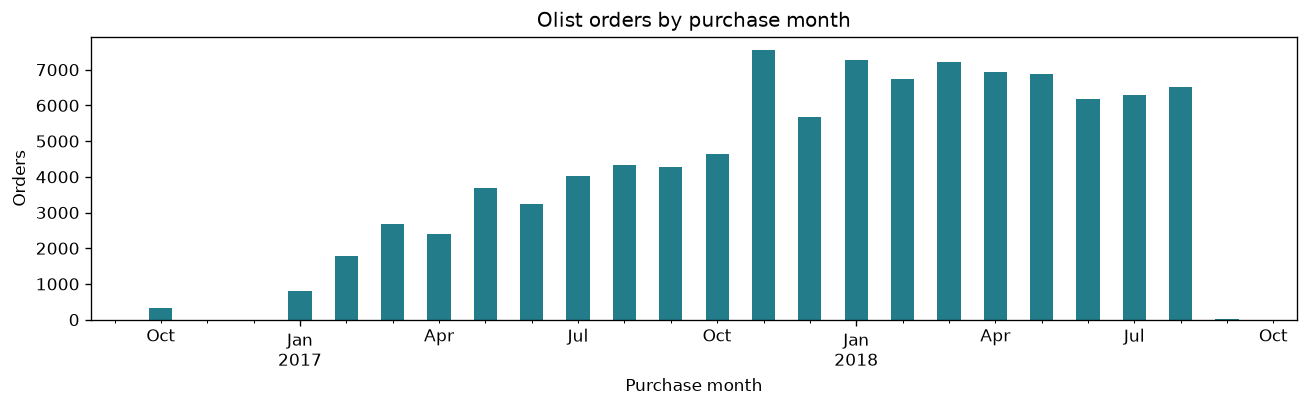

In [ ]:
purchase_month = dates["orders"]["order_purchase_timestamp"].dt.to_period("M")
months = pd.period_range(purchase_month.min(), purchase_month.max(), freq="M")
monthly_orders = purchase_month.value_counts().reindex(months, fill_value=0)
display(monthly_orders.rename_axis("purchase_month").rename("orders").to_frame())

ax = monthly_orders.plot.bar(figsize=(11, 3.5), color="#227C89")
ax.set(title="Olist orders by purchase month", xlabel="Purchase month", ylabel="Orders")
plt.tight_layout()
plt.show()

Inspect order status

In [42]:
order_dates = dates["orders"]
review_dates = dates["order_reviews"]
inversions = pd.Series({
    "Approval before purchase": (order_dates["order_approved_at"] < order_dates["order_purchase_timestamp"]).sum(),
    "Carrier handoff before purchase": (order_dates["order_delivered_carrier_date"] < order_dates["order_purchase_timestamp"]).sum(),
    "Customer delivery before purchase": (order_dates["order_delivered_customer_date"] < order_dates["order_purchase_timestamp"]).sum(),
    "Customer delivery before carrier handoff": (order_dates["order_delivered_customer_date"] < order_dates["order_delivered_carrier_date"]).sum(),
    "Review answer before creation": (review_dates["review_answer_timestamp"] < review_dates["review_creation_date"]).sum(),
    "Delivered status without actual date": (tables["orders"]["order_status"].eq("delivered") & order_dates["order_delivered_customer_date"].isna()).sum(),
})
display(tables["orders"]["order_status"].value_counts().rename("orders"))
display(inversions.rename("rows"))

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: orders, dtype: Int64

Approval before purchase                      0
Carrier handoff before purchase             166
Customer delivery before purchase             0
Customer delivery before carrier handoff     23
Review answer before creation                 0
Delivered status without actual date          8
Name: rows, dtype: int64

Check numeric values

In [49]:
def profile_number(name, column, pattern):
    source = tables[name][column].dropna()
    numeric = pd.to_numeric(source, errors="coerce")
    valid_shape = source.str.fullmatch(pattern)
    return {
        "column": f"{name}.{column}",
        "unparseable": numeric.isna().sum(),
        "unexpected_format": (~valid_shape).sum(),
        "min": numeric.min(),
        "max": numeric.max(),
        "zero": numeric.eq(0).sum(),
        "negative": numeric.lt(0).sum(),
    }

integer = r"[+-]?\d+"
money = r"[+-]?\d+(?:\.\d{1,2})?"
product_columns = tables["products"].columns.difference(["product_id", "product_category_name"])
checks = [
    ("order_items", "price", money), ("order_items", "freight_value", money),
    ("order_items", "order_item_id", integer), ("order_payments", "payment_value", money),
    ("order_payments", "payment_installments", integer), ("order_payments", "payment_sequential", integer),
    ("order_reviews", "review_score", integer),
]
checks += [("products", column, integer) for column in product_columns]
display(pd.DataFrame([profile_number(*check) for check in checks]))
display(tables["order_payments"]["payment_type"].value_counts().rename("payment_rows"))
display(tables["order_reviews"]["review_score"].value_counts().sort_index().rename("review_rows"))

,column,unparseable,unexpected_format,min,max,zero,negative
0,order_items.price,0,0,0.85,6735.00,0,0
1,order_items.freight_value,0,0,0.00,409.68,383,0
2,order_items.order_item_id,0,0,1.00,21.00,0,0
3,order_payments.payment_value,0,0,0.00,13664.08,9,0
4,order_payments.payment_installments,0,0,0.00,24.00,2,0
5,order_payments.payment_sequential,0,0,1.00,29.00,0,0
6,order_reviews.review_score,0,0,1.00,5.00,0,0
7,products.product_description_lenght,0,0,4.00,3992.00,0,0
8,products.product_height_cm,0,0,2.00,105.00,0,0
9,products.product_length_cm,0,0,7.00,105.00,0,0


payment_type
credit_card    76795
boleto         19784
voucher         5775
debit_card      1529
not_defined        3
Name: payment_rows, dtype: Int64

review_score
1    11424
2     3151
3     8179
4    19142
5    57328
Name: review_rows, dtype: Int64

In [ ]:
def to_cents(values):
    return pd.to_numeric(values).mul(100).round().astype("int64")

item_totals = (to_cents(tables["order_items"]["price"]) + to_cents(tables["order_items"]["freight_value"])).groupby(tables["order_items"]["order_id"]).sum()
payment_totals = to_cents(tables["order_payments"]["payment_value"]).groupby(tables["order_payments"]["order_id"]).sum()

totals = pd.concat(
    [item_totals.rename("item_and_freight_cents"), payment_totals.rename("payment_cents")],
    axis=1,
)
comparable = totals.dropna()
gap = (comparable["payment_cents"] - comparable["item_and_freight_cents"]).abs()
display(pd.Series({
    "Orders with both": len(comparable),
    "Exact match": gap.eq(0).sum(),
    "Exactly BRL 0.01 apart": gap.eq(1).sum(),
    "More than BRL 0.01 apart": gap.gt(1).sum(),
    "Items only": totals["payment_cents"].isna().sum(),
    "Payments only": totals["item_and_freight_cents"].isna().sum(),
}, name="orders"))

Orders with both            98665
Exact match                 98089
Exactly BRL 0.01 apart        273
More than BRL 0.01 apart      303
Items only                      1
Payments only                 775
Name: orders, dtype: int64

Inspect geolocation grain and ZIP joins

In [43]:
geo_prefix = tables["geolocation"]["geolocation_zip_code_prefix"]
geo_state = tables["geolocation"]["geolocation_state"]
zip_frequency = geo_prefix.value_counts()
zip_state_frequency = tables["geolocation"].groupby([geo_prefix, geo_state]).size()

lat = pd.to_numeric(tables["geolocation"]["geolocation_lat"], errors="coerce")
lng = pd.to_numeric(tables["geolocation"]["geolocation_lng"], errors="coerce")
valid_world = lat.between(-90, 90) & lng.between(-180, 180)
inside_brazil_box = lat.between(-35, 6) & lng.between(-75, -28)

display(pd.Series({
    "Invalid five-digit ZIP format": (~geo_prefix.str.fullmatch(r"[0-9]{5}").fillna(False)).sum(),
    "Invalid coordinates by world bounds": (~valid_world).sum(),
    "Valid coordinates outside approximate Brazil box": (valid_world & ~inside_brazil_box).sum(),
    "Distinct ZIP prefixes": len(zip_frequency),
    "ZIP prefixes with multiple rows": zip_frequency.gt(1).sum(),
    "Maximum rows per ZIP prefix": zip_frequency.max(),
    "Distinct ZIP and state pairs": len(zip_state_frequency),
    "ZIP and state pairs with multiple rows": zip_state_frequency.gt(1).sum(),
}, name="count"))

Invalid five-digit ZIP format                           0
Invalid coordinates by world bounds                     0
Valid coordinates outside approximate Brazil box       29
Distinct ZIP prefixes                               19015
ZIP prefixes with multiple rows                     17972
Maximum rows per ZIP prefix                          1146
Distinct ZIP and state pairs                        19023
ZIP and state pairs with multiple rows              17972
Name: count, dtype: int64

,source_rows,invalid_zip_format,no_zip_match,no_zip_and_state_match,rows_after_raw_zip_inner_join
entity,,,,,
customers,99441,0,278,278,15083455
sellers,3095,0,7,42,435087


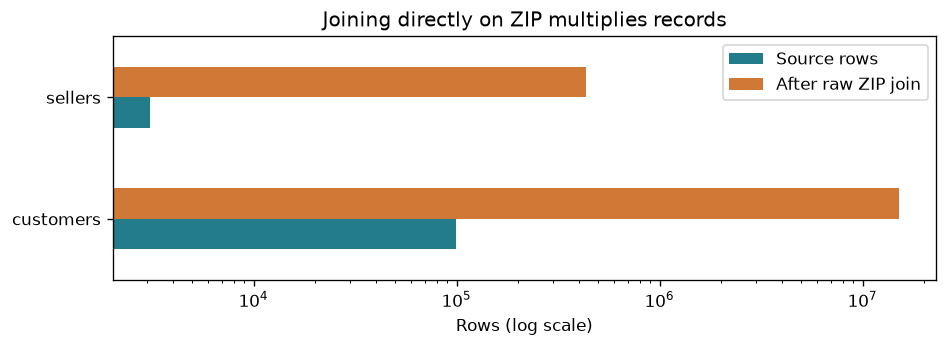

In [ ]:
def zip_coverage(name, prefix_column, state_column):
    source = tables[name]
    prefix = source[prefix_column]
    matches = prefix.map(zip_frequency).fillna(0)
    pairs = pd.MultiIndex.from_frame(source[[prefix_column, state_column]])
    return {
        "entity": name,
        "source_rows": len(source),
        "invalid_zip_format": (~prefix.str.fullmatch(r"[0-9]{5}").fillna(False)).sum(),
        "no_zip_match": matches.eq(0).sum(),
        "no_zip_and_state_match": (~pairs.isin(zip_state_frequency.index)).sum(),
        "rows_after_raw_zip_inner_join": int(matches.sum()),
    }

coverage = pd.DataFrame([
    zip_coverage("customers", "customer_zip_code_prefix", "customer_state"),
    zip_coverage("sellers", "seller_zip_code_prefix", "seller_state"),
]).set_index("entity")
display(coverage)

ax = coverage[["source_rows", "rows_after_raw_zip_inner_join"]].rename(columns={
    "source_rows": "Source rows",
    "rows_after_raw_zip_inner_join": "After raw ZIP join",
}).plot.barh(logx=True, figsize=(8, 3), color=["#227C89", "#D07937"])
ax.set(title="Joining directly on ZIP multiplies records", xlabel="Rows (log scale)", ylabel="")
plt.tight_layout()
plt.show()

## 8. Review before drawing the ERD

| Finding | Design question |
|---|---|
| Payments can repeat per order, and `(order_id, payment_sequential)` is unique. Reviews can repeat per order too, and `(order_id, review_id)` was unique in this snapshot. | Use separate child entities. Decide how reporting should summarize multiple rows without double counting. |
| 610 products lack a category and 13 have a category without an English translation. | Keep the original category and use an optional translation lookup. |
| Geolocation has 1,000,163 rows, including 261,831 exact duplicate excess rows. ZIP and state together still repeat. | Give geolocation observations their own grain. Define a one-row lookup before enriching customers or sellers. |
| Delivery timestamps can be missing or out of sequence, and the latest item shipping limit is in 2020. The first and last purchase months are sparse. | Preserve the source values, flag timing exceptions, and assess month coverage before comparing trends. |
| Of 98,665 orders with items and payments, 303 differ by more than BRL 0.01. | Keep both amounts visible for investigation and use fixed-precision database types. |

**For review:** Which findings should reject a batch, which should raise a warning, and which should only affect reporting?